# Customer Segmentation

## 1. Objective

The objective of this analysis is to identify customer groups with similar purchasing characteristics and customer behavior.

The segmentation is designed to support differentiated customer strategies by identifying meaningful differences in customer value, purchase history, and customer experience.

The resulting customer segments will be evaluated for statistical and business relevance before being translated into actionable business recommendations.

### Load Dataset

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [7]:
df = pd.read_csv("../data/processed/trendOne_clean.csv")

## 2. Segmentation Approach

Customer segmentation will be performed using an unsupervised clustering approach.

The analysis will group customers based on similarities across selected behavioral and customer value variables. The segmentation features will be selected based on business relevance, analytical suitability, data quality, and interpretability.

The number of clusters will not be predetermined. Candidate cluster solutions will be evaluated using clustering diagnostics such as the Elbow Method and Silhouette Score.

After clustering, the resulting segments will be profiled using both the segmentation variables and additional customer characteristics that were not used as clustering inputs.

## 3. Feature Selection

### 3.1 Segmentation Objective

The segmentation aims to identify groups of customers with similar purchasing characteristics and customer behavior.

The segmentation should provide meaningful differentiation across customer value, purchase history, and customer experience while remaining interpretable and actionable for business decision-making.

### 3.2 Segmentation Selection Criteria

Candidate segmentation variables are evaluated based on the following criteria:

1. **Business relevance**  
   The variable should represent a meaningful aspect of customer behavior or value.

2. **Behavioral relevance**  
   The variable should help distinguish customers based on purchasing or engagement characteristics.

3. **Actionability**  
   Differences between customer groups should potentially support differentiated business strategies.

4. **Data quality**  
   The variable should have acceptable completeness, consistency, and reliability.

5. **Variability**  
   The variable should provide sufficient variation across customers to contribute to meaningful grouping.

6. **Redundancy**  
   Highly redundant variables should be avoided when they provide substantially overlapping information.

7. **Interpretability**  
   The resulting customer segments should remain understandable from a business perspective.

### 3.3 Candidate Features

In [16]:
candidate_features = [
    "purchase_amount_usd",
    "previous_purchases",
    "review_rating"
]

df[candidate_features].describe().T

,count,mean,std,min,25%,50%,75%,max
purchase_amount_usd,3900.0,59.764359,23.685392,20.0,39.0,60.0,81.0,100.0
previous_purchases,3900.0,25.351538,14.447125,1.0,13.0,25.0,38.0,50.0
review_rating,3863.0,3.750065,0.716983,2.5,3.1,3.8,4.4,5.0


Three variables were selected as the primary inputs for customer segmentation: `purchase_amount_usd`, `previous_purchases`, and `review_rating`.

`purchase_amount_usd` captures differences in recorded purchase value, while `previous_purchases` provides information about customers' prior purchasing history. `review_rating` adds a customer-experience dimension that is not directly represented by the other two variables.

These features were chosen because they fulfill the seven segmentation criteria we need and represent three different customer dimensions.

In [18]:
df[candidate_features].isna().sum()

purchase_amount_usd     0
previous_purchases      0
review_rating          37
dtype: int64

In [19]:
df[candidate_features].nunique()

purchase_amount_usd    81
previous_purchases     50
review_rating          26
dtype: int64

In [20]:
df[candidate_features].corr(method="spearman")

,purchase_amount_usd,previous_purchases,review_rating
purchase_amount_usd,1.000000,0.008315,0.029429
previous_purchases,0.008315,1.000000,0.003796
review_rating,0.029429,0.003796,1.000000


Spearman correlation was used to assess potential redundancy among the candidate segmentation variables.

The results show negligible monotonic relationships between all candidate feature pairs:

- Purchase Amount vs Previous Purchases: ρ = 0.008
- Purchase Amount vs Review Rating: ρ = 0.029
- Previous Purchases vs Review Rating: ρ = 0.004

These results indicate that the candidate variables provide relatively distinct information and do not show evidence of strong monotonic redundancy.

However, correlation alone is not sufficient to determine the final segmentation features. Data quality, variability, distribution, and business relevance are also considered before final feature selection.

## 4. Feature Preparation

### 4.1 Create Segmentation Dataset

Since we plan to perform clustering later, we need a complete feature matrix because clustering algorithms require complete data. Since only about 0.95% of the review ratings are missing, I will handle these missing values by imputing them with the median review rating

In [25]:
seg_features = [
    "purchase_amount_usd",
    "previous_purchases",
    "review_rating"
]

seg_columns = ['customer_id'] + seg_features

df_seg = df[seg_columns].copy()

assert df_seg['customer_id'].is_unique
assert df_seg['customer_id'].notna().all()

In [26]:
df_seg['review_rating_was_missing'] = (
    df_seg["review_rating"].isna()
)

df_seg['review_rating_original'] = (
    df_seg['review_rating']
)

### 4.2 Asses Missing Values

In [28]:
df_seg.isna().sum()

customer_id                   0
purchase_amount_usd           0
previous_purchases            0
review_rating                37
review_rating_was_missing     0
review_rating_original       37
dtype: int64

### 4.3 Handle Missing Values

In [30]:
df_seg['review_rating'] = (
    df_seg['review_rating']
    .fillna(df_seg['review_rating'].median())
)

assert df_seg[seg_features].notna().all().all()

print("Rows:", len(df_seg))
print("Originally missing ratings:", df_seg['review_rating_was_missing'].sum())
print("Median used:", df_seg['review_rating'].median())

Rows: 3900
Originally missing ratings: 37
Median used: 3.8


In [31]:
df_seg.info()

<class 'pandas.DataFrame'>
RangeIndex: 3900 entries, 0 to 3899
Data columns (total 6 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   customer_id                3900 non-null   int64  
 1   purchase_amount_usd        3900 non-null   int64  
 2   previous_purchases         3900 non-null   int64  
 3   review_rating              3900 non-null   float64
 4   review_rating_was_missing  3900 non-null   bool   
 5   review_rating_original     3863 non-null   float64
dtypes: bool(1), float64(2), int64(3)
memory usage: 156.3 KB


## 5. Feature Exploration

### 5.1 Descriptive Statistics

In [34]:
df_seg[seg_features].describe().T

,count,mean,std,min,25%,50%,75%,max
purchase_amount_usd,3900.0,59.764359,23.685392,20.0,39.0,60.0,81.0,100.0
previous_purchases,3900.0,25.351538,14.447125,1.0,13.0,25.0,38.0,50.0
review_rating,3900.0,3.750538,0.713589,2.5,3.1,3.8,4.4,5.0


### 5.2 Distribution Analysis

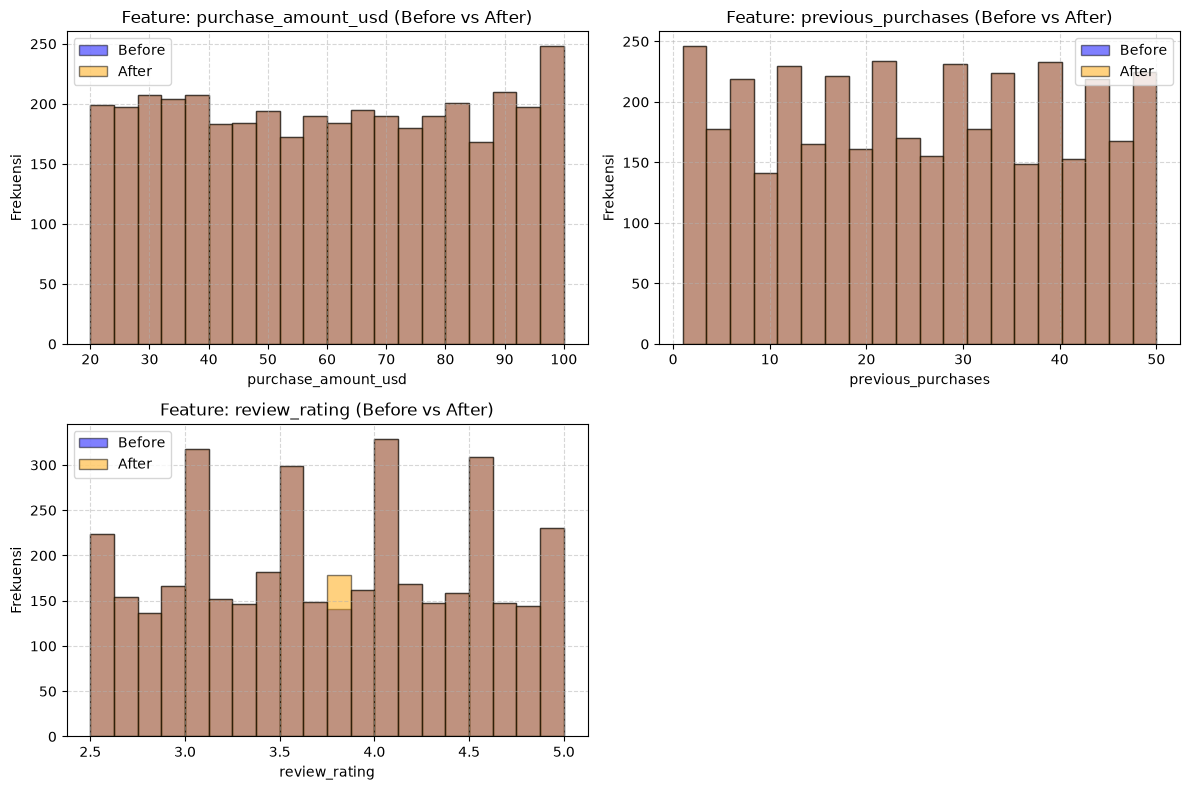

In [36]:
n_features = len(seg_features)

fig, axes = plt.subplots(nrows=(n_features + 1) // 2, ncols=2, figsize=(12, 8))
axes = axes.flatten() 

for i, feature in enumerate(seg_features):
    ax = axes[i]
    
    ax.hist(df[feature], bins=20, alpha=0.5, label='Before', color='blue', edgecolor='black')
    ax.hist(df_seg[feature], bins=20, alpha=0.5, label='After', color='orange', edgecolor='black')
    
    ax.set_title(f'Feature: {feature} (Before vs After)', fontsize=12)
    ax.set_xlabel(feature)
    ax.set_ylabel('Frekuensi')
    ax.legend()
    ax.grid(True, linestyle='--', alpha=0.5)


for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

The histogram above shows the distribution of review ratings after missing values were imputed using the median rating.

## 6. Feature Scaling

K-Means is a distance based clustering algorithm that assigns observations to clusters based on their distances from cluster centroids. Consequently, differences in the scale and range of input features can influence the clustering results.

The selected segmentation features have different measurement scales:

- `purchase_amount_usd`: ranges from 20 to 100 USD.
- `previous_purchases`: ranges from 1 to 50 purchases.
- `review_rating`: ranges from 2.5 to 5.0.

Without scaling, features with larger numerical ranges may contribute more strongly to the distance calculations, potentially dominating the clustering process. This could cause the resulting segments to be driven disproportionately by purchase amount or previous purchase count rather than reflecting a balanced combination of the selected customer dimensions.

To reduce this scale related influence, the selected features are standardized before applying K-Means.

### 6.1 Prepare Feature Matrix

In [41]:
X = df_seg[seg_features].copy()

### 6.2 Apply StandardScaler

Here, I am using StandardScaler for the feature scaling. StandardScaler transforms each feature by subtracting its mean and dividing by its standard deviation.

$
z = \frac{x-\mu}{\sigma}
$

After standardization, each feature has a mean approximately equal to 0 and a standard deviation approximately equal to 1, subject to numerical precision.

Standardization places the selected features on a comparable scale while preserving their relative ordering and linear relationships within each individual feature.

In [44]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

### 6.3 Validate Scaling

X_scaled_df = pd.DataFrame(
    X_scaled,
    columns=seg_features,
    index=X.index
)

X_scaled_df.describe().round(3).T

## 7. Determine Number of Clusters

### 7.1 Elbow Method

The Elbow Method evaluates how within-cluster sum of squares (WCSS), commonly represented by K-Means inertia, changes as the number of clusters increases.

As (k) increases, inertia generally decreases because observations are assigned to a larger number of clusters. The objective is to identify a point where additional clusters provide progressively smaller reductions in inertia.

However, the elbow may not be clearly defined. In that case, inertia alone is insufficient to determine the number of clusters, and other evaluation criteria should also be considered.

In [50]:
k_values = range(2,10)

inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    inertias.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

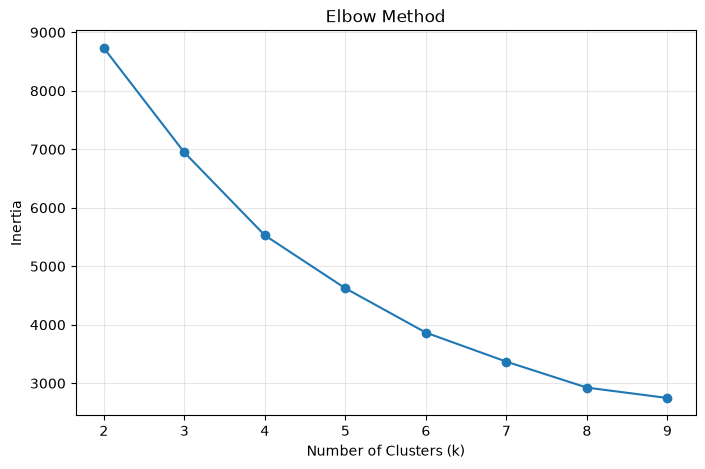

In [51]:
plt.figure(figsize=(8, 5))
plt.plot(
    list(k_values),
    inertias,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()

### 7.2 Silhouette Analysis

Silhouette Analysis evaluates how well each observation fits within its assigned cluster compared with other clusters.

The silhouette coefficient ranges from -1 to 1:

Values close to 1 indicate that observations are generally closer to their assigned cluster than to neighboring clusters.

Values around 0 indicate overlapping clusters or observations near cluster boundaries.

Negative values suggest that some observations may be closer to another cluster.

The mean silhouette score is used to compare candidate values of (k). A higher score indicates better separation and cohesion according to this metric, but it does not necessarily imply greater business usefulness.

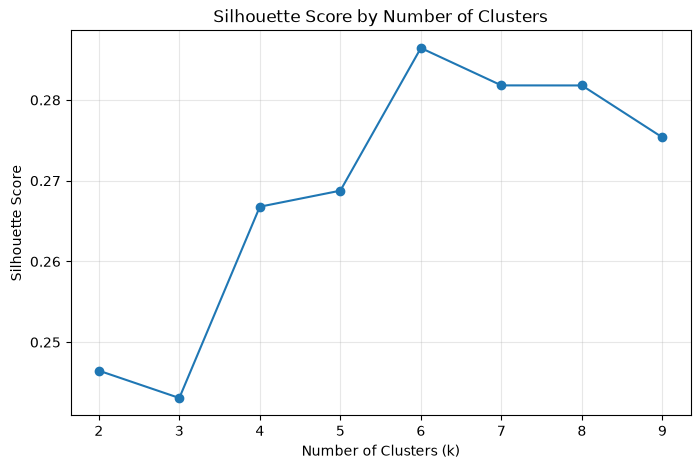

In [54]:
plt.figure(figsize=(8, 5))
plt.plot(
    list(k_values),
    silhouette_scores,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score by Number of Clusters")
plt.xticks(list(k_values))
plt.grid(alpha=0.3)
plt.show()

In [55]:
candidate_results = []

for k in range(4,7):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=20
    )

    labels = model.fit_predict(X_scaled)

    cluster_sizes = pd.Series(labels).value_counts()

    candidate_results.append({
        "k": k,
        "inertia": model.inertia_,
        "silhouette_score": silhouette_score(
            X_scaled, labels
        ),
        "smallest_cluster_size": cluster_sizes.min(),
        "largest_cluster_size": cluster_sizes.max(),
        "smallest_cluster_pct": (
            cluster_sizes.min() / len(labels) * 100
        )
    })

pd.DataFrame(candidate_results).round(4)

,k,inertia,silhouette_score,smallest_cluster_size,largest_cluster_size,smallest_cluster_pct
0,4,5528.8567,0.2669,953,1034,24.4359
1,5,4623.6972,0.2688,672,848,17.2308
2,6,3865.6855,0.2864,625,673,16.0256


Six clusters are retained as the operational choice for completing this exploratory analysis. Among the evaluated candidates, k = 6 achieved the highest observed silhouette score of 0.2864 and produced relatively balanced cluster sizes.

However, the silhouette score indicates limited separation, and the initialization-based stability assessment showed variability in the resulting assignments. Therefore, k = 6 is a practical project decision rather than evidence of an optimal or naturally occurring six-segment customer structure.

## 8. Customer Segmentation

Based on the comparative evaluation in Section 7, six clusters were selected as the operational configuration for this project.

This decision does not imply that six clusters provide strong separation or represent the objectively optimal structure of the dataset. Rather, (k = 6) was considered a reasonable choice among the evaluated alternatives based on the observed silhouette scores, inertia, cluster sizes, and the intended level of segmentation detail.

The final K-Means model is fitted using the standardized segmentation features:

- `purchase_amount_usd`
- `previous_purchases`
- `review_rating`

The model uses random_state=42 to make the initialization reproducible and n_init=20 to run multiple centroid initializations and retain the solution with the lowest inertia.

### 8.1 Kmeans Segmentation

In [60]:
kmeans = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=20
)

cluster_labels = kmeans.fit_predict(X_scaled)

### 8.2 Assign Cluster Labels

After fitting the model, each customer is assigned to one of the six clusters.

The resulting cluster labels are model-generated identifiers ranging from 0 to 5. These labels represent group membership and do not indicate a ranking, value, or quality of the customers.

The labels will subsequently be used to profile customer characteristics, interpret differences between groups, and develop cautious business implications.

In [63]:
df_seg['cluster'] = cluster_labels

### 8.3 Validate Assignments

In [65]:
df_seg['cluster'].value_counts().sort_index()

cluster
0    647
1    673
2    665
3    646
4    625
5    644
Name: count, dtype: int64

In [66]:
df_seg.sample(5)

,customer_id,purchase_amount_usd,previous_purchases,review_rating,review_rating_was_missing,review_rating_original,cluster
2788,2789,92,2,3.1,False,3.1,4
622,623,63,44,4.0,False,4.0,3
92,93,87,13,4.4,False,4.4,0
1885,1886,53,35,4.4,False,4.4,5
1227,1228,37,19,4.9,False,4.9,5


In [67]:
assert df_seg["cluster"].notna().all()
assert df_seg["customer_id"].is_unique
assert df_seg["cluster"].nunique() == 6

## 9. Cluster Validation

### 9.1 Cluster Size

In [70]:
cluster_sizes = (
    df_seg["cluster"]
    .value_counts()
    .sort_index()
    .rename("customer_count")
    .to_frame()
)

cluster_sizes["percentage"] = (
    cluster_sizes["customer_count"]
    / len(df_seg) * 100
).round(2)

cluster_sizes

,customer_count,percentage
cluster,,
0,647,16.59
1,673,17.26
2,665,17.05
3,646,16.56
4,625,16.03
5,644,16.51


### 9.2 Silhoutte Score

In [72]:
final_silhouette = silhouette_score(
    X_scaled,
    df_seg["cluster"]
)

print(f"Final silhouette score: {final_silhouette:.4f}")

Final silhouette score: 0.2864


### 9.3 Stability and Validation Limitations

The initialization based stability assessment produced a mean Adjusted Rand Index (ARI) of 0.5145 for k = 6, with a standard deviation of 0.2411 across the evaluated initialization comparisons.

The results indicate that the clustering assignments are not fully consistent across all tested initializations. This assessment evaluates sensitivity to initialization only and does not establish stability under changes in the sampled customer population.

The clustering solution should therefore be interpreted cautiously. A resampling-based stability assessment has not been completed, and the observed cluster structure has not been established as a stable representation of the underlying customer population.

##  10. Cluster Profiling

### 10.1 Numerical Profile

In [77]:
cluster_profile = (
    df_seg
    .groupby("cluster")[seg_features]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

cluster_profile

purchase_amount_usd                      previous_purchases         \
                      count   mean median    std              count   mean   
cluster                                                                      
0                       647  76.00   77.0  14.56                647  12.11   
1                       673  45.99   45.0  15.24                673  38.88   
2                       665  39.48   39.0  12.18                665  11.90   
3                       646  80.33   81.0  12.75                646  39.76   
4                       625  82.77   83.0  10.96                625  20.78   
5                       644  35.84   35.0  10.56                644  28.39   

                      review_rating                     
        median    std         count  mean median   std  
cluster                                                 
0         11.0   7.57           647  4.34    4.4  0.39  
1         39.0   7.14           673  3.15    3.1  0.39  
2         12.0   7.23           665  3.31    3.3  0.48  
3         41.0   7.03           646  4.22    4.2  0.47  
4         20.0  11.26           625  3.06    3.0  0.34  
5         29.0  11.62           644  4.43    4.5  0.34

### 10.2 Categorical Profile

In [79]:
profiling_features = [
    "age",
    "gender",
    "region",
    "category",
    "subscription_status",
    "discount_applied",
    "frequency_of_purchases"
]

In [80]:
available_profiling_features = [
    col for col in profiling_features
    if col in df.columns
]

profile_data = df_seg[
    ["customer_id", "cluster"]
].merge(
    df[['customer_id'] + available_profiling_features],
    on="customer_id",
    how="left",
    validate="one_to_one"
)

In [81]:
subscription_profile = pd.crosstab(
    profile_data['cluster'],
    profile_data['subscription_status'],
    normalize="index"
).mul(100).round(2)

subscription_profile

subscription_status,No,Yes
cluster,,
0,73.26,26.74
1,70.73,29.27
2,75.19,24.81
3,73.22,26.78
4,72.80,27.20
5,72.83,27.17


In [82]:
discount_profile = pd.crosstab(
    profile_data['cluster'],
    profile_data['discount_applied'],
    normalize="index"
).mul(100).round(2)

discount_profile

discount_applied,No,Yes
cluster,,
0,55.49,44.51
1,53.05,46.95
2,58.50,41.50
3,58.51,41.49
4,58.08,41.92
5,58.54,41.46


In [83]:
region_profile = pd.crosstab(
    profile_data['cluster'],
    profile_data['region'],
    normalize="index"
).mul(100).round(2)

region_profile

region,Midwest,Northeast,South,West
cluster,,,,
0,23.49,17.93,34.00,24.57
1,23.03,15.45,34.32,27.19
2,23.46,18.65,33.08,24.81
3,24.61,16.10,32.20,27.09
4,25.60,16.80,30.40,27.20
5,24.07,18.79,31.37,25.78


## 11. Segment Interpretation

### 11.1 Segment Naming Criteria

Cluster labels are descriptive identifiers generated by the algorithm and do not inherently represent business segments.

Descriptive segment names will be assigned after examining each cluster's purchase amount, purchase history, review rating, and relevant profiling variables. Names should reflect observed characteristics, remain neutral, and avoid unsupported claims about loyalty, profitability, customer lifetime value, or promotional responsiveness.

The labels are intended for exploratory interpretation and should not be treated as validated operational customer categories.

### 11.2 Customer Segment Labels

|Cluster ID|Description                          |
|----------|:-----------------------------------:|
|0         |Higher-Spend, Lower Purchase History |
|1         |Repeat-History, Lower-Rating         |
|2         |Lower-Spend, Lower Purchase History  |
|3         |Higher-Spend, Higher Purchase History|
|4         |Higher-Spend, Lower-Rating           |
|5         |Lower-Spend, Higher-Rating           |

In [89]:
segment_name_map = {
    0: "Higher-Spend, Lower Purchase History",
    1: "Repeat-History, Lower-Rating",
    2: "Lower-Spend, Lower Purchase History",
    3: "Higher-Spend, Higher Purchase History",
    4: "Higher-Spend, Lower-Rating",
    5: "Lower-Spend, Higher-Rating"
}

df_seg['segment_name'] = (
    df_seg['cluster']
    .map(segment_name_map)
)

In [90]:
df_seg[
    [
        "customer_id",
        "cluster",
        "segment_name",
        "purchase_amount_usd",
        "previous_purchases",
        "review_rating"
    ]
].head(10)

,customer_id,cluster,segment_name,purchase_amount_usd,previous_purchases,review_rating
0,1,2,"Lower-Spend, Lower Purchase History",53,14,3.1
1,2,2,"Lower-Spend, Lower Purchase History",64,2,3.1
2,3,4,"Higher-Spend, Lower-Rating",73,23,3.1
3,4,3,"Higher-Spend, Higher Purchase History",90,49,3.5
4,5,1,"Repeat-History, Lower-Rating",49,31,2.7
5,6,2,"Lower-Spend, Lower Purchase History",20,14,2.9
6,7,3,"Higher-Spend, Higher Purchase History",85,49,3.2
7,8,2,"Lower-Spend, Lower Purchase History",34,19,3.2
8,9,4,"Higher-Spend, Lower-Rating",97,8,2.6
9,10,5,"Lower-Spend, Higher-Rating",31,4,4.8


In [91]:
assert df_seg["segment_name"].notna().all()

In [92]:
customer_segments = df_seg[
    [
        "customer_id",
        "cluster",
        "segment_name",
        "purchase_amount_usd",
        "previous_purchases",
        "review_rating",
        "review_rating_was_missing"
    ]
].copy()

customer_segments.head()

,customer_id,cluster,segment_name,purchase_amount_usd,previous_purchases,review_rating,review_rating_was_missing
0,1,2,"Lower-Spend, Lower Purchase History",53,14,3.1,False
1,2,2,"Lower-Spend, Lower Purchase History",64,2,3.1,False
2,3,4,"Higher-Spend, Lower-Rating",73,23,3.1,False
3,4,3,"Higher-Spend, Higher Purchase History",90,49,3.5,False
4,5,1,"Repeat-History, Lower-Rating",49,31,2.7,False


## 12. Business Implications

The resulting clusters provide an exploratory view of customer differences across purchase amount, purchase history, and review rating.

Potential business applications include investigating high spend customers with limited purchase history, examining customers with relatively high purchase history but lower ratings, and understanding customers who report high ratings despite lower purchase amounts.

These observations may help formulate follow-up business questions. However, the clusters do not establish customer loyalty, profitability, future purchasing behavior, or the effectiveness of discounts and subscriptions.

The dataset does not contain transaction timestamps or sufficient outcome information to validate retention, customer lifetime value, or future revenue implications. Therefore, the segment profiles should be used as exploratory hypotheses rather than direct targeting rules.

## 13. Summary & Next Steps

K-Means was applied to the TrendOne customer dataset using purchase amount, previous purchases, and review rating. The analysis retained six clusters as a practical choice for completing the exploratory workflow.

The resulting clusters differ descriptively across the selected features. However, the highest observed silhouette score was 0.2864, and the initialization-based stability assessment showed variability in cluster assignments.

The findings suggest that the dataset supports an exploratory grouping of customers, but the available evidence is insufficient to establish six naturally distinct, stable, or operationally validated customer segments.

Future work should consider transaction-level data with timestamps, richer behavioral variables, and independent validation of the resulting segments before operational deployment.

In [136]:
customer_segments.to_csv("../outputs/customer_segments.csv", index=False)